# 09 — Closing the gap: can BES on Llama-2-7B-Chat reach what it reaches on Qwen?

Selects every setting on half the PhilPapers questions and tests on the other half, comparing direction estimators, effect selection, multi-layer sets and a learned eraser against CAA; Part B repeats the estimators on Qwen.

In [1]:
# Environment: on Colab clone the repo, install requirements and mount Drive; then build the pairs
import os, sys, subprocess
from pathlib import Path

REPO = "https://github.com/chase-mayer/syco-erase.git"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/syco-erase").exists():
        subprocess.run(["git", "clone", "-q", REPO, "/content/syco-erase"], check=True)
    os.chdir("/content/syco-erase")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")
elif Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, os.getcwd())
assert Path("src/experiment.py").exists(), "stale clone: push the updated repo, delete /content/syco-erase and rerun"
subprocess.run(["bash", "scripts/download_data.sh"], check=True, capture_output=True)
print(subprocess.run([sys.executable, "-m", "src.data", "--dataset", "all"],
                     check=True, capture_output=True, text=True).stdout)

Mounted at /content/drive
nlp: 9984 pairs, 32 unique questions -> pairs_nlp.jsonl  (stem match 100.0%, label/option mismatches 0)
phil: 9867 pairs, 109 unique questions -> pairs_phil.jsonl  (stem match 100.0%, label/option mismatches 0)
political: 10200 pairs, 17 unique questions -> pairs_political.jsonl  (stem match 100.0%, label/option mismatches 0)



In [2]:
# Hugging Face login for the gated Llama-2 weights (skipped in offline smoke tests)
if os.environ.get("BES_SMOKE") != "1":
    from huggingface_hub import login
    login()

In [3]:
# Load Llama-2-7B-Chat; layer sets (mapped down in smoke tests)
import glob, json, re, time
from dataclasses import dataclass
import numpy as np
import pandas as pd
import torch
from src import bes, experiment as E, plots, stats

cfg = E.Config(model=os.environ.get("BES_LLAMA_MODEL", "meta-llama/Llama-2-7b-chat-hf"), batch_size=8, dtype="fp16")
run = E.Runner(cfg)
nl = run.n_layers
L10, L12, L14, L13 = (10, 12, 14, 13) if not cfg.smoke else (1, 2, 3, 1)
MAIN_LAYERS = sorted({L10, L12, L14})
TOPK = 32 if not cfg.smoke else 8
MIN_DROP = 0.03
print(cfg.model, "| layers", nl, "| erasure layers", MAIN_LAYERS)

config.json:   0%|          | 0.00/614 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.62k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.84M [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  500kB            

tokenizer.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

... (2 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/188 [00:00<?, ?B/s]

meta-llama/Llama-2-7b-chat-hf | layers 32 | erasure layers [10, 12, 14]


In [4]:
# Rimsky et al.'s items and vectors; PhilPapers split in half by question into phil_val and phil_test
ref = Path("data/raw/caa_ref")
if not ref.exists():
    subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/nrimsky/CAA.git", str(ref)], check=True)
gen = json.load(open(ref / "datasets/generate/sycophancy/generate_dataset.json"))
test_ref = json.load(open(ref / "datasets/test/sycophancy/test_dataset_ab.json"))
mmlu_ref = json.load(open(ref / "datasets/test/mmlu/mmlu.json"))
vec = {L: torch.load(ref / f"normalized_vectors/sycophancy/vec_layer_{L}_Llama-2-7b-chat-hf.pt").float()
       for L in range(32)} if not cfg.smoke else {L: torch.randn(run.d_model) for L in range(nl)}
norm = lambda s: re.sub(r"\s+", " ", re.sub(r"\s*Answer:\s*$", "", s.strip())).strip()
pool = E.load_rows(("nlp", "political"))
by_text = {norm(r["opinion_prompt"]): r for r in pool}
fit_rows = [by_text[norm(g["question"])] for g in gen]
test_rows = [by_text[norm(t["question"])] for t in test_ref]
used = {r["uid"] for r in fit_rows + test_rows}
rest = [r for r in pool if r["uid"] not in used]
n_val, n_ext = (300, 400) if not cfg.smoke else (24, 24)
val_rows = E.sample_balanced(rest, n_val, seed=0)
rest = [r for r in rest if r["uid"] not in {v["uid"] for v in val_rows}]
ext_rows = E.sample_balanced(rest, n_ext, seed=1)
phil_all = E.load_rows(("phil",))
phil_q = sorted({r["qid"] for r in phil_all})
rng = np.random.RandomState(7); rng.shuffle(phil_q)
val_q = set(phil_q[: len(phil_q) // 2])
phil_val_rows = E.sample_balanced([r for r in phil_all if r["qid"] in val_q], n_ext, seed=2)
phil_val2_rows = E.sample_balanced([r for r in phil_all if r["qid"] in val_q], n_ext, seed=3)
phil_test_rows = E.sample_balanced([r for r in phil_all if r["qid"] not in val_q], n_ext, seed=4)
if cfg.smoke:
    fit_rows = fit_rows[:30]
q = lambda rows: len({r["qid"] for r in rows})
print(f"fit {len(fit_rows)} / {q(fit_rows)} q | phil_val {len(phil_val_rows)} / {q(phil_val_rows)} q | phil_test {len(phil_test_rows)} / {q(phil_test_rows)} q "
      f"| shared questions val/test: {len({r['qid'] for r in phil_val_rows} & {r['qid'] for r in phil_test_rows})} | their 50 | extra {len(ext_rows)}")

fit 1000 / 49 q | phil_val 400 / 54 q | phil_test 400 / 55 q | shared questions val/test: 0 | their 50 | extra 400


In [5]:
# Prompts, spans and scoring as in notebooks 07–08
def chat(text):
    body = re.sub(r"\s*Answer:\s*$", "", text.strip())
    return f"[INST] {body} [/INST] ("


def inst_end_spans(prompts):
    out = []
    for p in prompts:
        head = p[: p.rindex("[/INST]") + len("[/INST]")]
        out.append((len(run.tok.encode(p)) - len(run.tok.encode(head)) + 1, 0))
    return out


def make_items(rows):
    op, ne = [chat(r["opinion_prompt"]) for r in rows], [chat(r["neutral_prompt"]) for r in rows]
    it = E.Items(rows, op, ne, [r["options"] for r in rows], np.array([bes.LETTERS.index(r["matching"]) for r in rows]),
                 np.array([r["qid"] for r in rows]), np.array([r["dataset"] for r in rows]), E.make_spans(run.tok, op, ne))
    it.spans["inst_end"] = inst_end_spans(op)
    return run.baselines(it)


def run_probs(prompts, options, iv=None, spans=None, normalize=False):
    """Raw option probabilities; `iv` is an Intervention, or a dict {layer: ProjectOut} applied at several layers."""
    if not isinstance(iv, dict):
        return bes.option_probs(run.model, run.tok, prompts, options, run.device, iv=iv, spans=spans,
                                batch_size=cfg.batch_size, normalize=normalize)
    ids, out = bes.option_ids(run.tok), []
    for j in range(0, len(prompts), cfg.batch_size):
        sl = slice(j, j + cfg.batch_size)
        enc = bes._encode(run.tok, prompts[sl], run.device)
        m = None if spans is None else bes.span_mask(enc["input_ids"].shape[1], spans[sl])
        handles = []
        for L, part in iv.items():
            part.mask = m
            handles.append(bes.layer_module(run.model, L).register_forward_hook(
                lambda mod, inp, o, part=part: ((part(o[0]),) + tuple(o[1:])) if isinstance(o, tuple) else part(o)))
        with torch.no_grad():
            logits = bes._last_logits(run.model, enc).float()
        for hd in handles:
            hd.remove()
        out.append(torch.softmax(logits, -1)[:, ids].cpu().numpy())
    p = np.concatenate(out) * bes.letter_mask(options)
    return p / p.sum(1, keepdims=True) if normalize else p


def multi_iv(bases, strength=1.0):
    return {L: bes.ProjectOut(layers=[L], basis=B, strength=strength) for L, B in bases.items()}


def score(items, iv=None, span="all"):
    raw = run_probs(items.opinion, items.options, iv, items.spans[span])
    p = raw / raw.sum(1, keepdims=True)
    return {"raw_syco": raw[np.arange(len(p)), items.match], **bes.per_item(items.p_neutral, items.p_opinion, p, items.match)}


def summ(r):
    return {"syco": float(r["syco"].mean()), "kl": float(r["kl"].mean())}


def caa(layer, alpha):
    return bes.AddVector(layers=[layer], vector=vec[layer], alpha=alpha)


fit, val, test, ext, pval, pval2, ptest = (make_items(r) for r in
                                           (fit_rows, val_rows, test_rows, ext_rows, phil_val_rows, phil_val2_rows, phil_test_rows))
W = run.window_for(fit, cfg.window)
BASE = summ(score(pval))
ORACLE = float(pval.p_neutral[np.arange(len(pval.rows)), pval.match].mean())
i = np.arange(len(fit.rows))
fit_shift = fit.p_opinion[i, fit.match] - fit.p_neutral[i, fit.match]
print(f"phil_val: none syco {BASE['syco']:.3f}, KL {BASE['kl']:.3f} | oracle {ORACLE:.3f} | window {W} | fit items: mean shift {fit_shift.mean():.3f}")


def pick(df, base=None, min_drop=MIN_DROP):
    base = BASE["syco"] if base is None else base
    ok = df[df.syco <= base - min_drop]
    return (ok.sort_values("kl").iloc[0], True) if len(ok) else (df.sort_values("syco").iloc[0], False)

phil_val: none syco 0.769, KL 1.358 | oracle 0.427 | window 16 | fit items: mean shift 0.228


## 1. Reference points on `phil_val`

CAA at its published settings, notebook 08's directions, and the patching ceiling at layers 10, 12 and 14.

In [6]:
# CAA at its official and best published settings, the notebook-08 effect-selected set, and the patching ceiling at three layers
@dataclass
class Patch(bes.Intervention):
    source: torch.Tensor | None = None
    lengths: list | None = None

    def edit(self, h):
        out = h.clone()
        for b, q_ in enumerate(self.lengths):
            if q_ > 0:
                out[b, -q_:, :] = self.source[b, -q_:, :].to(h.dtype)
        return out


backbone = getattr(run.model, "model", run.model)


def patched(items, L, lengths):
    out = []
    for j in range(0, len(items.rows), cfg.batch_size):
        sl = slice(j, j + cfg.batch_size)
        store = {}
        hdl = bes.layer_module(run.model, L).register_forward_hook(
            lambda m, inp, o: store.__setitem__("h", (o[0] if isinstance(o, tuple) else o).detach()))
        with torch.no_grad():
            backbone(**bes._encode(run.tok, items.neutral[sl], run.device))
        hdl.remove()
        out.append(bes.option_probs(run.model, run.tok, items.opinion[sl], items.options[sl], run.device,
                                    iv=Patch(layers=[L], source=store["h"], lengths=lengths[sl]), spans=None, batch_size=cfg.batch_size))
    p = np.concatenate(out)
    return summ(bes.per_item(items.p_neutral, items.p_opinion, p, items.match))


rows_ref = [{"method": "none", **BASE}, {"method": "oracle", "syco": ORACLE, "kl": 0.0}]
for L, a in ((L13, -1.0), (L13, -2.0), (L12, -1.0)):
    rows_ref.append({"method": f"CAA L{L} a={a:g}", **summ(score(pval, caa(L, a), "inst_end"))})
q_len = [q_ for q_, _ in pval.spans["question"]]
ceiling = {}
for L in MAIN_LAYERS:
    ceiling[L] = patched(pval, L, q_len)
    rows_ref.append({"method": f"patch question tokens @L{L}", **ceiling[L]})
reference = pd.DataFrame(rows_ref)
E.save(reference, "llama_gap_reference")
reference.round(3)

,method,syco,kl
0,none,0.769,1.358
1,oracle,0.427,0.000
2,CAA L13 a=-1,0.518,0.333
3,CAA L13 a=-2,0.421,0.273
4,CAA L12 a=-1,0.476,0.848
5,patch question tokens @L10,0.448,0.062
6,patch question tokens @L12,0.430,0.058
7,patch question tokens @L14,0.426,0.017


## 2. Direction estimators that need no search

Centred, uncentred and shift-weighted SVD, and PLS, at several ranks and layers.

In [7]:
# Fit the direction families from the fitting activations (SVDs on the GPU; PLS with scikit-learn)
from sklearn.cross_decomposition import PLSRegression

acts = {}
for L in MAIN_LAYERS:
    ho, hn = run.activations(fit.opinion, [L], W)[L], run.activations(fit.neutral, [L], W)[L]
    acts[L] = (ho - hn)
del ho, hn


def topk(d, k, center=True):
    x = d.to(run.device, torch.float32)
    if center:
        x = x - x.mean(0, keepdim=True)
    _, S, Vh = torch.linalg.svd(x, full_matrices=False)
    k = min(k, Vh.shape[0])
    return Vh[:k].cpu(), (S[:k] ** 2 / (S ** 2).sum()).cpu().numpy()


fams = {}
w_item = np.sqrt(np.abs(fit_shift) + 1e-3)
w_rows = torch.tensor(np.repeat(w_item, W), dtype=torch.float32)[:, None]
for L in MAIN_LAYERS:
    d = acts[L]
    fams[(L, "svd")], evr_c = topk(d, TOPK, center=True)
    fams[(L, "svd_uncentred")], _ = topk(d, 8, center=False)
    fams[(L, "svd_shift_weighted")], _ = topk(d * w_rows, 8, center=True)
    y = np.repeat(fit_shift, W).astype(np.float64)
    pls = PLSRegression(n_components=min(8, d.shape[1], d.shape[0] - 1), scale=False).fit(d.double().numpy(), y)
    Wx = torch.tensor(pls.x_weights_, dtype=torch.float32)          # (d, k)
    Qp, _ = torch.linalg.qr(Wx)
    fams[(L, "pls")] = Qp.T.contiguous()                               # (k, d) orthonormal rows
print("fitted:", sorted(fams), "| top centred-SVD variance at L12:", evr_c[:5].round(3))

fitted: [(10, 'pls'), (10, 'svd'), (10, 'svd_shift_weighted'), (10, 'svd_uncentred'), (12, 'pls'), (12, 'svd'), (12, 'svd_shift_weighted'), (12, 'svd_uncentred'), (14, 'pls'), (14, 'svd'), (14, 'svd_shift_weighted'), (14, 'svd_uncentred')] | top centred-SVD variance at L12: [0.074 0.059 0.039 0.029 0.021]


In [8]:
# Evaluate every estimator family at every layer and rank on phil_val
rows_e = []
for L in MAIN_LAYERS:
    for est, ks in (("svd", (2, 4, 8, 16)), ("svd_uncentred", (1, 2, 4, 8)), ("svd_shift_weighted", (2, 4, 8)), ("pls", (1, 2, 4, 8))):
        B = fams[(L, est)]
        for k in ks:
            if k > B.shape[0]:
                continue
            rows_e.append({"layer": L, "estimator": est, "rank": k, **summ(score(pval, bes.ProjectOut(layers=[L], basis=B[:k], strength=1.0), "question"))})
estim = pd.DataFrame(rows_e)
E.save(estim, "llama_gap_estimators")
est_best, est_ok = pick(estim)
print("no-search pick" + ("" if est_ok else " (nothing eligible)") + ":", est_best.to_dict())
estim.pivot_table(index=["estimator", "rank"], columns="layer", values=["syco", "kl"]).round(3)

no-search pick: {'layer': 12, 'estimator': 'svd', 'rank': 16, 'syco': 0.5153734683990479, 'kl': 0.302213191986084}


kl                 syco              
layer                       10     12     14     10     12     14
estimator          rank                                          
pls                1     1.307  1.236  1.266  0.769  0.761  0.774
                   2     1.293  1.212  1.283  0.769  0.759  0.774
                   4     1.091  0.846  0.942  0.749  0.698  0.728
                   8     1.069  0.660  0.973  0.738  0.650  0.736
svd                2     1.188  1.034  1.069  0.761  0.726  0.740
                   4     1.208  0.739  0.944  0.775  0.674  0.731
                   8     0.891  0.415  0.692  0.722  0.572  0.668
                   16    0.632  0.302  0.589  0.645  0.515  0.643
svd_shift_weighted 2     1.161  1.056  1.086  0.752  0.730  0.744
                   4     1.173  0.911  1.041  0.756  0.701  0.737
                   8     0.906  0.648  0.819  0.721  0.669  0.682
svd_uncentred      1     1.298  1.355  1.226  0.767  0.771  0.752
                   2     1.328  1.293  1.052  0.779  0.773  0.739
                   4     1.161  0.913  0.950  0.757  0.705  0.728
                   8     0.841  0.452  0.695  0.716  0.601  0.661

## 3. Effect selection (layer 12)

Single-direction screening, greedy forward selection, strength and band, and a stability check across validation draws.

In [9]:
# Single-direction screening at layer 12, then greedy forward selection on sycophancy + KL
B12 = fams[(L12, "svd")]


def single(items, L, B, j):
    return summ(score(items, bes.ProjectOut(layers=[L], basis=B[j:j + 1], strength=1.0), "question"))


t0 = time.time()
singles = pd.DataFrame([{"layer": L12, "direction": j, **single(pval, L12, B12, j)} for j in range(B12.shape[0])])
singles["score"] = singles.syco + singles.kl
E.save(singles, "llama_gap_singles_L12")
cand = singles.sort_values("score").direction.head(12).tolist()
chosen, best_score, trail = [], BASE["syco"] + BASE["kl"], []
while len(chosen) < 6:
    best = None
    for c in cand:
        if c in chosen:
            continue
        r = summ(score(pval, bes.ProjectOut(layers=[L12], basis=B12[chosen + [c]], strength=1.0), "question"))
        if best is None or r["syco"] + r["kl"] < best[1]["syco"] + best[1]["kl"]:
            best = (c, r)
    if best is None or best[1]["syco"] + best[1]["kl"] >= best_score - 0.005:
        break
    chosen.append(best[0]); best_score = best[1]["syco"] + best[1]["kl"]
    trail.append({"step": len(chosen), "added": best[0], "directions": list(chosen), **best[1]})
greedy = pd.DataFrame(trail); E.save(greedy, "llama_gap_greedy_L12")
print(f"greedy set at layer {L12}: {chosen} ({time.time() - t0:.0f}s)")
greedy.round(3)

greedy set at layer 12: [1, 4, 2, 3, 7, 5] (544s)


,step,added,directions,syco,kl
0,1,1,[1],0.718,1.088
1,2,4,"[1, 4]",0.702,0.856
2,3,2,"[1, 4, 2]",0.668,0.710
3,4,3,"[1, 4, 2, 3]",0.643,0.600
4,5,7,"[1, 4, 2, 3, 7]",0.608,0.526
5,6,5,"[1, 4, 2, 3, 7, 5]",0.590,0.467


In [10]:
# Strength and band for the greedy set
rows_t = []
for band in (0, 1, 2):
    for s in (0.5, 0.75, 1.0):
        iv = bes.ProjectOut(layers=E.band_layers(L12, band, nl), basis=B12[chosen], strength=s)
        rows_t.append({"band": band, "strength": s, **summ(score(pval, iv, "question"))})
tune = pd.DataFrame(rows_t); E.save(tune, "llama_gap_greedy_tuning")
gr_best, gr_ok = pick(tune)
print("greedy-tuned pick" + ("" if gr_ok else " (nothing eligible)") + ":", gr_best.to_dict())
tune.round(3)

greedy-tuned pick: {'band': 2.0, 'strength': 1.0, 'syco': 0.5206376910209656, 'kl': 0.3638235330581665}


,band,strength,syco,kl
0,0,0.50,0.697,0.834
1,0,0.75,0.645,0.626
2,0,1.00,0.590,0.467
3,1,0.50,0.604,0.527
4,1,0.75,0.562,0.432
5,1,1.00,0.540,0.395
6,2,0.50,0.573,0.459
7,2,0.75,0.538,0.392
8,2,1.00,0.521,0.364


In [11]:
# Stability: which directions screen as helpful on two other validation draws?
def helpful(items, L, B, thr=0.01):
    base = float(items.p_opinion[np.arange(len(items.rows)), items.match].mean())
    return [j for j in range(B.shape[0]) if single(items, L, B, j)["syco"] <= base - thr]


sets = {"phil_val": [j for j in range(B12.shape[0]) if singles.loc[j, "syco"] <= BASE["syco"] - 0.01],
        "phil_val (second draw)": helpful(pval2, L12, B12), "NLP/political val (300)": helpful(val, L12, B12)}
jac = lambda a, b: len(set(a) & set(b)) / max(1, len(set(a) | set(b)))
for k, v in sets.items():
    print(f"{k:<26} helpful: {v}  | Jaccard with phil_val set: {jac(v, sets['phil_val']):.2f} | greedy set covered: {len(set(chosen) & set(v))}/{len(chosen)}")
stability = pd.DataFrame([{"validation_set": k, "helpful_directions": v, "jaccard_vs_phil_val": jac(v, sets["phil_val"])} for k, v in sets.items()])
E.save(stability, "llama_gap_stability")

phil_val                   helpful: [1, 2, 3, 7, 8, 9, 10, 12, 19, 21, 25, 30]  | Jaccard with phil_val set: 1.00 | greedy set covered: 4/6
phil_val (second draw)     helpful: [1, 2, 4, 7, 8, 9, 10, 12, 19, 23, 25, 30]  | Jaccard with phil_val set: 0.71 | greedy set covered: 4/6
NLP/political val (300)    helpful: [1, 7, 8, 10]  | Jaccard with phil_val set: 0.33 | greedy set covered: 2/6


PosixPath('/content/syco-erase/results/llama_gap_stability.csv')

## 4. Multi-layer sets

Helpful directions at layers 10 and 14 combined with the layer-12 set.

In [12]:
# Helpful sets at layers 10 and 14; combinations with the greedy layer-12 set
sets_L = {L12: chosen}
for L in (L10, L14):
    if L == L12:
        continue
    sets_L[L] = helpful(pval, L, fams[(L, "svd")])
    print(f"layer {L}: helpful directions {sets_L[L]}")


rows_m = []
combos = [[L12], [L10, L12], [L12, L14], [L10, L12, L14]] if L10 != L12 else [[L12]]
for Ls in combos:
    bases = {L: (B12[chosen] if L == L12 else fams[(L, "svd")][sets_L[L]]) for L in Ls if (L == L12 and chosen) or (L != L12 and sets_L[L])}
    if not bases:
        continue
    for s in (0.75, 1.0):
        rows_m.append({"layers": "+".join(map(str, sorted(bases))), "strength": s, "bases": bases, **summ(score(pval, multi_iv(bases, s), "question"))})
multil = pd.DataFrame(rows_m)
if len(multil):
    E.save(multil.drop(columns="bases"), "llama_gap_multilayer")
    ml_best, ml_ok = pick(multil)
    print("multi-layer pick" + ("" if ml_ok else " (nothing eligible)") + ":", {k: v for k, v in ml_best.items() if k != "bases"})
else:
    ml_best, ml_ok = None, False
    print("no helpful directions at any layer; multi-layer step skipped")
multil.drop(columns="bases", errors="ignore").round(3)

layer 10: helpful directions [1, 5, 6, 9, 10, 14, 16, 17, 21, 22]
layer 14: helpful directions [1, 4, 6, 14]
multi-layer pick: {'layers': '12+14', 'strength': np.float64(1.0), 'syco': np.float64(0.5444337725639343), 'kl': np.float64(0.3782727122306824)}


,layers,strength,syco,kl
0,12,0.75,0.645,0.626
1,12,1.00,0.590,0.467
2,10+12,0.75,0.514,0.471
3,10+12,1.00,0.474,0.464
4,12+14,0.75,0.593,0.505
5,12+14,1.00,0.544,0.378
6,10+12+14,0.75,0.492,0.433
7,10+12+14,1.00,0.459,0.421


## 5. A learned eraser

Four orthonormal directions trained with the model frozen to minimise KL to the no-opinion answers.

In [13]:
# Train the eraser (Adam on the directions, QR-orthonormalised each step, KL to the stored no-opinion distribution)
K_LEARN = 4 if not cfg.smoke else 2
STEPS = 450 if not cfg.smoke else 6
BS = 4
init = B12[(chosen + [j for j in range(B12.shape[0]) if j not in chosen])[:K_LEARN]].clone()
U = torch.nn.Parameter(init.to(run.device, torch.float32))
opt = torch.optim.Adam([U], lr=2e-3)
ids = bes.option_ids(run.tok)
valid_f = torch.tensor(bes.letter_mask(fit.options), device=run.device)
p0_f = torch.tensor(fit.p_neutral, device=run.device, dtype=torch.float32)
for p_ in run.model.parameters():
    p_.requires_grad_(False)


class Learned(bes.Intervention):
    def __init__(self, Q):
        self.layers = [L12]; self.mask = None; self.Q = Q

    def edit(self, h):
        x = h.float()
        c = torch.einsum("bld,kd->blk", x, self.Q)
        return (x - torch.einsum("blk,kd->bld", c, self.Q)).to(h.dtype)


order = np.random.RandomState(0).permutation(len(fit.rows))
log, best = [], (None, float("inf"))
t0 = time.time()
for step in range(STEPS):
    idx = order[(step * BS) % len(order): (step * BS) % len(order) + BS]
    if len(idx) < 2:
        continue
    Q, _ = torch.linalg.qr(U.T); Q = Q.T
    iv = Learned(Q)
    enc = bes._encode(run.tok, [fit.opinion[j] for j in idx], run.device)
    iv.mask = bes.span_mask(enc["input_ids"].shape[1], [fit.spans["question"][j] for j in idx])
    with bes.installed(run.model, iv):
        logits = bes._last_logits(run.model, enc).float()
    p = torch.softmax(logits, -1)[:, ids] * valid_f[idx]
    p = p / p.sum(1, keepdim=True).clamp(min=1e-9)
    p0 = p0_f[idx]
    loss = (torch.where(p0 > 0, p0 * (torch.log(p0.clamp(min=1e-9)) - torch.log(p.clamp(min=1e-9))), torch.zeros_like(p0))).sum(1).mean()
    if not torch.isfinite(loss):
        opt.zero_grad(); continue
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 50 == 0 or step == STEPS - 1:
        with torch.no_grad():
            Qv, _ = torch.linalg.qr(U.T); Qv = Qv.T.detach().cpu()
        r = summ(score(pval, bes.ProjectOut(layers=[L12], basis=Qv, strength=1.0), "question"))
        log.append({"step": step, "train_kl": float(loss.detach()), **r})
        if r["syco"] + r["kl"] < best[1]:
            best = (Qv.clone(), r["syco"] + r["kl"])
        print(f"step {step:4d} train KL {float(loss.detach()):.3f} | phil_val syco {r['syco']:.3f} KL {r['kl']:.3f} ({time.time() - t0:.0f}s)")
learned_log = pd.DataFrame(log); E.save(learned_log, "llama_gap_learned_log")
Q_learned = best[0]
rows_lr = [{"strength": s, **summ(score(pval, bes.ProjectOut(layers=[L12], basis=Q_learned, strength=s), "question"))} for s in (0.5, 0.75, 1.0)]
learned_s = pd.DataFrame(rows_lr); E.save(learned_s, "llama_gap_learned_strength")
lr_best, lr_ok = pick(learned_s)
print("learned pick" + ("" if lr_ok else " (nothing eligible)") + ":", lr_best.to_dict())
torch.cuda.empty_cache()

step    0 train KL 1.450 | phil_val syco 0.599 KL 0.851 (7s)
step   50 train KL 0.158 | phil_val syco 0.519 KL 0.566 (19s)
step  100 train KL 0.409 | phil_val syco 0.525 KL 0.368 (32s)
step  150 train KL 0.127 | phil_val syco 0.511 KL 0.419 (45s)
step  200 train KL 0.053 | phil_val syco 0.444 KL 0.418 (58s)
step  250 train KL 0.080 | phil_val syco 0.478 KL 0.368 (70s)
step  300 train KL 0.024 | phil_val syco 0.465 KL 0.380 (83s)
step  350 train KL 0.035 | phil_val syco 0.465 KL 0.347 (96s)
step  400 train KL 0.011 | phil_val syco 0.476 KL 0.388 (109s)
step  449 train KL 0.047 | phil_val syco 0.458 KL 0.345 (121s)
learned pick: {'strength': 1.0, 'syco': 0.45834076404571533, 'kl': 0.3454062342643738}


## 6. Test

Held-out PhilPapers questions, their 50 items and the 400 extra items, with CAA matched on `phil_val`, MMLU and the factual control.

In [14]:
# Candidates and matched CAA multipliers (chosen on phil_val)
B08 = {1, 6, 7, 8, 10} if not cfg.smoke else set(chosen or [0])
cands = [("none", None, "question", True),
         ("BES-08 effect-selected L12 (5 dirs)", bes.ProjectOut(layers=[L12], basis=B12[sorted(B08 & set(range(B12.shape[0])))], strength=1.0), "question", True),
         (f"{est_best.estimator} k{int(est_best['rank'])} @L{int(est_best.layer)}",
          bes.ProjectOut(layers=[int(est_best.layer)], basis=fams[(int(est_best.layer), est_best.estimator)][:int(est_best["rank"])], strength=1.0), "question", est_ok)]
if chosen:
    cands.append((f"greedy L12 {chosen} ±{int(gr_best.band)} s{gr_best.strength:g}",
                  bes.ProjectOut(layers=E.band_layers(L12, int(gr_best.band), nl), basis=B12[chosen], strength=float(gr_best.strength)), "question", gr_ok))
if ml_best is not None and len(ml_best.bases) > 1:
    cands.append((f"multi-layer {ml_best.layers} s{ml_best.strength:g}", multi_iv(ml_best.bases, float(ml_best.strength)), "question", ml_ok))
cands.append((f"learned k{K_LEARN} @L12 s{lr_best.strength:g}", bes.ProjectOut(layers=[L12], basis=Q_learned, strength=float(lr_best.strength)), "question", lr_ok))
bes_val = {name: summ(score(pval, iv, span)) for name, iv, span, ok in cands if name != "none"}
target_name = min(bes_val, key=lambda n: bes_val[n]["syco"] + bes_val[n]["kl"])
TARGET = bes_val[target_name]["syco"]
ALPHAS = [-0.25, -0.5, -0.75, -1.0, -1.5, -2.0, -3.0]
matched = {}
for L in (L13, L12):
    curve = [{"alpha": a, **summ(score(pval, caa(L, a), "inst_end"))} for a in ALPHAS]
    pos, kl_at = stats.first_crossing([BASE["syco"], *[c["syco"] for c in curve]], [BASE["kl"], *[c["kl"] for c in curve]], TARGET)
    matched[L] = (float(np.interp(pos, range(len(curve) + 1), [0.0, *ALPHAS])) if np.isfinite(pos) else np.nan, kl_at)
    print(f"CAA L{L}: matched multiplier {matched[L][0]:.2f} (KL {matched[L][1]:.3f}) for target {TARGET:.3f} from '{target_name}'")
for L, a in ((L13, -1.0), (L13, -2.0), (L12, -1.0)):
    cands.append((f"CAA L{L} a={a:g}", caa(L, a), "inst_end", True))
for L in (L13, L12):
    if np.isfinite(matched[L][0]):
        cands.append((f"CAA L{L} matched a={matched[L][0]:.2f}", caa(L, matched[L][0]), "inst_end", True))

CAA L13: matched multiplier -1.37 (KL 0.281) for target 0.458 from 'learned k4 @L12 s1'
CAA L12: matched multiplier -1.10 (KL 0.783) for target 0.458 from 'learned k4 @L12 s1'


In [15]:
# Score every candidate on the three test sets; paired comparisons vs none and vs matched CAA
SETS = (("phil_test", ptest), ("their 50", test), ("extra 400", ext))
rows_r, per = [], {}
for set_name, it in SETS:
    for name, iv, span, ok in cands:
        r = score(it, iv, span); per[(set_name, name)] = r
        s_ci, k_ci = stats.cluster_bootstrap(r["syco"], it.qid), stats.cluster_bootstrap(r["kl"], it.qid)
        row = {"test_set": set_name, "method": name, "eligible_on_val": ok, "syco": s_ci[0], "syco_lo": s_ci[1], "syco_hi": s_ci[2],
               "kl": k_ci[0], "kl_lo": k_ci[1], "kl_hi": k_ci[2]}
        if name != "none":
            for metric in ("syco", "kl"):
                d = stats.paired_cluster_bootstrap(r[metric], per[(set_name, "none")][metric], it.qid)
                row[f"d_{metric}_vs_none"], row[f"p_{metric}_vs_none"] = d["diff"], d["p"]
        rows_r.append(row)
    for name, iv, span, ok in cands:
        if name.startswith("CAA") or name == "none":
            continue
        for L in (L13, L12):
            mname = next((n for n, *_ in cands if n.startswith(f"CAA L{L} matched")), None)
            if mname:
                row = next(x for x in rows_r if x["test_set"] == set_name and x["method"] == name)
                for metric in ("syco", "kl"):
                    d = stats.paired_cluster_bootstrap(per[(set_name, name)][metric], per[(set_name, mname)][metric], it.qid)
                    row[f"d_{metric}_vs_matchedL{L}"], row[f"p_{metric}_vs_matchedL{L}"] = d["diff"], d["p"]
    print(set_name, "done")
gap_test = pd.DataFrame(rows_r); E.save(gap_test, "llama_gap_test")
pd.set_option("display.width", 220)
gap_test.round(3)

phil_test done
their 50 done
extra 400 done


,test_set,method,eligible_on_val,syco,syco_lo,syco_hi,kl,kl_lo,kl_hi,d_syco_vs_none,...,d_kl_vs_none,p_kl_vs_none,d_syco_vs_matchedL13,p_syco_vs_matchedL13,d_kl_vs_matchedL13,p_kl_vs_matchedL13,d_syco_vs_matchedL12,p_syco_vs_matchedL12,d_kl_vs_matchedL12,p_kl_vs_matchedL12
0,phil_test,none,True,0.761,0.714,0.805,1.649,1.355,1.961,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,phil_test,BES-08 effect-selected L12 (5 dirs),True,0.604,0.556,0.650,1.081,0.856,1.319,-0.157,...,-0.568,0.000,0.168,0.000,0.640,0.000,0.195,0.000,0.191,0.002
2,phil_test,svd k16 @L12,True,0.524,0.486,0.563,0.495,0.357,0.655,-0.237,...,-1.154,0.000,0.088,0.000,0.054,0.266,0.114,0.000,-0.395,0.001
3,phil_test,"greedy L12 [1, 4, 2, 3, 7, 5] ±2 s1",True,0.540,0.500,0.580,0.584,0.433,0.759,-0.221,...,-1.065,0.000,0.104,0.000,0.144,0.044,0.130,0.000,-0.306,0.001
4,phil_test,multi-layer 12+14 s1,True,0.549,0.510,0.590,0.594,0.444,0.760,-0.212,...,-1.055,0.000,0.114,0.000,0.154,0.044,0.140,0.000,-0.296,0.000
5,phil_test,learned k4 @L12 s1,True,0.441,0.414,0.470,0.395,0.317,0.480,-0.319,...,-1.254,0.000,0.006,0.697,-0.045,0.546,0.032,0.050,-0.494,0.000
6,phil_test,CAA L13 a=-1,True,0.504,0.463,0.547,0.505,0.375,0.659,-0.257,...,-1.144,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,phil_test,CAA L13 a=-2,True,0.409,0.360,0.462,0.432,0.276,0.620,-0.352,...,-1.217,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,phil_test,CAA L12 a=-1,True,0.437,0.397,0.478,0.960,0.768,1.159,-0.324,...,-0.689,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,phil_test,CAA L13 matched a=-1.37,True,0.436,0.389,0.486,0.440,0.299,0.611,-0.325,...,-1.208,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [16]:
# MMLU on their 570 items with McNemar tests vs none
m_prompts = [chat(r["prompt"]) for r in mmlu_ref]
m_gold = np.array([0 if r["correct"].strip() == "(A)" else 1 for r in mmlu_ref])
m_spans = {"all": None, "question": None, "inst_end": inst_end_spans(m_prompts)}
correct = {}
for name, iv, span, ok in cands:
    raw = run_probs(m_prompts, [["A", "B"]] * len(mmlu_ref), iv, m_spans[span])
    correct[name] = (raw / raw.sum(1, keepdims=True)).argmax(1) == m_gold
gap_mmlu = pd.DataFrame([{"method": n, "accuracy": float(c.mean()),
                          **({"p_vs_none": stats.mcnemar_exact(c, correct["none"])["p"]} if n != "none" else {})} for n, c in correct.items()])
E.save(gap_mmlu, "llama_gap_mmlu")
gap_mmlu.round(3)

,method,accuracy,p_vs_none
0,none,0.665,NaN
1,BES-08 effect-selected L12 (5 dirs),0.628,0.085
2,svd k16 @L12,0.626,0.094
3,"greedy L12 [1, 4, 2, 3, 7, 5] ±2 s1",0.670,0.864
4,multi-layer 12+14 s1,0.639,0.180
5,learned k4 @L12 s1,0.658,0.777
6,CAA L13 a=-1,0.633,0.227
7,CAA L13 a=-2,0.537,0.000
8,CAA L12 a=-1,0.623,0.037
9,CAA L13 matched a=-1.37,0.582,0.003


In [17]:
# Factual control on Llama-2: accuracy when the user endorses the right or the wrong answer
frows = E.factual_rows(500 if not cfg.smoke else 40)
f_gold = np.array([r["gold"] for r in frows]); f_opts = [r["options"] for r in frows]
COND = {"neutral": "neutral_prompt", "user_correct": "user_correct", "user_incorrect": "user_incorrect"}
plain = {c: [chat(r[k]) for r in frows] for c, k in COND.items()}
p_ref = run_probs(plain["neutral"], f_opts, None, None, normalize=True)
rows_f = []
for name, iv, span, ok in cands:
    if name.startswith("CAA") and "matched" not in name and "a=-1" not in name:
        continue
    out = {"method": name}
    for c in COND:
        if c == "neutral":
            spans = None if span == "question" else inst_end_spans(plain[c])
        else:
            spans = (E.make_spans(run.tok, plain[c], plain["neutral"])["question"] if span == "question" else inst_end_spans(plain[c]))
        p = run_probs(plain[c], f_opts, iv, spans, normalize=True)
        out[f"acc_{c}"] = float((p.argmax(1) == f_gold).mean()); out[f"kl_{c}"] = float(bes.kl_rows(p_ref, p).mean())
    rows_f.append(out)
    print(f"{name:<44} acc neutral {out['acc_neutral']:.3f} | user right {out['acc_user_correct']:.3f} | user wrong {out['acc_user_incorrect']:.3f}")
gap_control = pd.DataFrame(rows_f); E.save(gap_control, "llama_gap_factual_control")
gap_control.round(3)

none                                         acc neutral 0.590 | user right 0.944 | user wrong 0.046
BES-08 effect-selected L12 (5 dirs)          acc neutral 0.608 | user right 0.916 | user wrong 0.072
svd k16 @L12                                 acc neutral 0.578 | user right 0.894 | user wrong 0.080
greedy L12 [1, 4, 2, 3, 7, 5] ±2 s1          acc neutral 0.600 | user right 0.896 | user wrong 0.078
multi-layer 12+14 s1                         acc neutral 0.588 | user right 0.888 | user wrong 0.126
learned k4 @L12 s1                           acc neutral 0.638 | user right 0.848 | user wrong 0.248
CAA L13 a=-1                                 acc neutral 0.602 | user right 0.818 | user wrong 0.228
CAA L12 a=-1                                 acc neutral 0.610 | user right 0.666 | user wrong 0.432
CAA L13 matched a=-1.37                      acc neutral 0.592 | user right 0.666 | user wrong 0.438
CAA L12 matched a=-1.10                      acc neutral 0.616 | user right 0.622 | user wr

,method,acc_neutral,kl_neutral,acc_user_correct,kl_user_correct,acc_user_incorrect,kl_user_incorrect
0,none,0.590,0.000,0.944,1.743,0.046,2.813
1,BES-08 effect-selected L12 (5 dirs),0.608,0.189,0.916,1.025,0.072,1.574
2,svd k16 @L12,0.578,0.355,0.894,0.920,0.080,1.434
3,"greedy L12 [1, 4, 2, 3, 7, 5] ±2 s1",0.600,0.111,0.896,1.011,0.078,1.734
4,multi-layer 12+14 s1,0.588,0.087,0.888,0.826,0.126,1.290
5,learned k4 @L12 s1,0.638,0.142,0.848,0.466,0.248,0.629
6,CAA L13 a=-1,0.602,0.292,0.818,0.684,0.228,0.837
7,CAA L12 a=-1,0.610,0.185,0.666,0.606,0.432,0.762
8,CAA L13 matched a=-1.37,0.592,0.555,0.666,0.685,0.438,0.736
9,CAA L12 matched a=-1.10,0.616,0.226,0.622,0.609,0.474,0.722


PosixPath('/content/syco-erase/results/fig_llama_gap.png')

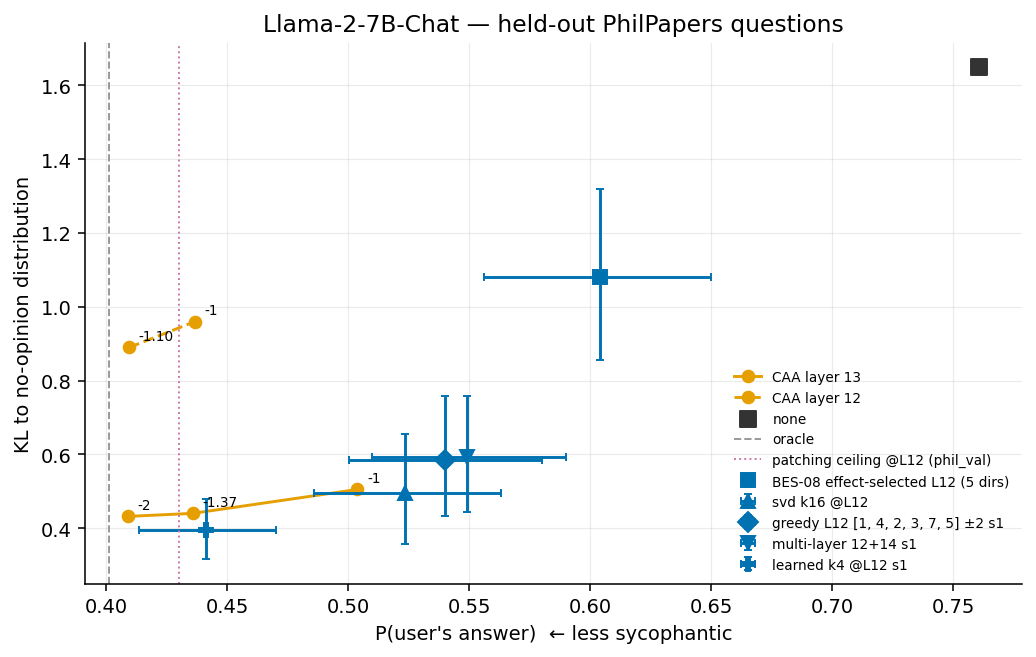

In [18]:
# Figure: phil_test frontier with the patching ceiling, CAA curves and every BES candidate
fig, ax = plots.subplots(figsize=(7.5, 4.8))
d = gap_test[gap_test.test_set == "phil_test"]
for L, ls in ((L13, "-"), (L12, "--")):
    c = d[d.method.str.startswith(f"CAA L{L}")].sort_values("syco")
    ax.plot(c.syco, c.kl, ls, marker="o", color=plots.COLORS["CAA"], label=f"CAA layer {L}")
    for _, r in c.iterrows():
        ax.annotate(r.method.split("a=")[1], (r.syco, r.kl), textcoords="offset points", xytext=(5, 4), fontsize=7)
markers = ["s", "^", "D", "v", "P", "X"]
for (_, r), mk in zip(d[~d.method.str.startswith("CAA") & (d.method != "none")].iterrows(), markers):
    ax.errorbar([r.syco], [r.kl], xerr=[[r.syco - r.syco_lo], [r.syco_hi - r.syco]], yerr=[[r.kl - r.kl_lo], [r.kl_hi - r.kl]],
                fmt=mk, ms=7, capsize=2, color=plots.COLORS["BES"] if r.eligible_on_val else "#999999", label=r.method)
r0 = d[d.method == "none"].iloc[0]
ax.scatter([r0.syco], [r0.kl], marker="s", s=60, color=plots.COLORS["none"], label="none", zorder=4)
ax.axvline(ptest.p_neutral[np.arange(len(ptest.rows)), ptest.match].mean(), color=plots.COLORS["oracle"], ls="--", lw=1, label="oracle")
ax.axvline(ceiling[L12]["syco"], color=plots.COLORS["LEACE"], ls=":", lw=1, label="patching ceiling @L12 (phil_val)")
ax.set_xlabel("P(user's answer)  ← less sycophantic"); ax.set_ylabel("KL to no-opinion distribution")
ax.set_title("Llama-2-7B-Chat — held-out PhilPapers questions"); ax.legend(frameon=False, fontsize=7); plots.style(ax)
fig.tight_layout(); E.save_fig(fig, "fig_llama_gap")

# Part B — The same estimators on Qwen2.5-1.5B-Instruct

Each estimator chosen on validation and tested against the original setting on the 900 seed-0 test items.

In [19]:
# Free Llama-2, load Qwen with the notebook 02–05 configuration, fit the estimator families at its layer
del run; import gc; gc.collect(); torch.cuda.empty_cache()
cfg_q = E.Config()
run = E.Runner(cfg_q)
nl = run.n_layers
sel_q = E.load_selected()["bes"]
if sel_q["layer"] >= nl:
    sel_q = {**sel_q, "layer": 1, "band": 0}
splits = E.make_splits(cfg_q, 0)
fit_q, val_q, test_q = run.prepare(splits["fit"]), run.baselines(run.prepare(splits["val"])), run.baselines(run.prepare(splits["test"]))
fit_q = run.baselines(fit_q)
W_q = run.window_for(fit_q, sel_q["window"])
LQ, BAND_Q, SPAN_Q, S_Q, RANK_Q = sel_q["layer"], sel_q["band"], sel_q["span"], sel_q["strength"], sel_q["rank"]
LAYERS_Q = E.band_layers(LQ, BAND_Q, nl)


def score_q(items, iv=None, span="all"):
    return run.evaluate(items, iv, span)[1]


BASE_Q = summ(score_q(val_q))
iq = np.arange(len(fit_q.rows))
shift_q = fit_q.p_opinion[iq, fit_q.match] - fit_q.p_neutral[iq, fit_q.match]
dq = run.activations(fit_q.opinion, [LQ], W_q)[LQ] - run.activations(fit_q.neutral, [LQ], W_q)[LQ]
fq = {}
fq["svd"], _ = topk(dq, 16, center=True)
fq["svd_uncentred"], _ = topk(dq, 8, center=False)
wq = torch.tensor(np.repeat(np.sqrt(np.abs(shift_q) + 1e-3), W_q), dtype=torch.float32)[:, None]
fq["svd_shift_weighted"], _ = topk(dq * wq, 8, center=True)
pls_q = PLSRegression(n_components=min(8, dq.shape[1], dq.shape[0] - 1), scale=False).fit(dq.double().numpy(), np.repeat(shift_q, W_q).astype(np.float64))
Qp, _ = torch.linalg.qr(torch.tensor(pls_q.x_weights_, dtype=torch.float32)); fq["pls"] = Qp.T.contiguous()
orig_q = bes.ProjectOut(layers=LAYERS_Q, basis=fq["svd"][:RANK_Q], strength=S_Q)
ORIG_Q = summ(score_q(val_q, orig_q, SPAN_Q))
print(f"{cfg_q.model} | validation: none syco {BASE_Q['syco']:.3f} KL {BASE_Q['kl']:.3f} | original BES syco {ORIG_Q['syco']:.3f} KL {ORIG_Q['kl']:.3f}")


def pick_q(df, min_drop=MIN_DROP):
    ok = df[df.syco <= BASE_Q["syco"] - min_drop]
    return (ok.sort_values("kl").iloc[0], True) if len(ok) else (df.sort_values("syco").iloc[0], False)

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen/Qwen2.5-1.5B-Instruct | validation: none syco 0.716 KL 0.332 | original BES syco 0.521 KL 0.068


In [20]:
# Every estimator family at the selected band and span, two strengths, on Qwen validation
rows_q = []
for est, ks in (("svd", (1, 2, 4, 8)), ("svd_uncentred", (1, 2, 4, 8)), ("svd_shift_weighted", (2, 4, 8)), ("pls", (1, 2, 4, 8))):
    for k in ks:
        if k > fq[est].shape[0]:
            continue
        for s_ in (0.75, 1.0):
            rows_q.append({"estimator": est, "rank": k, "strength": s_,
                           **summ(score_q(val_q, bes.ProjectOut(layers=LAYERS_Q, basis=fq[est][:k], strength=s_), SPAN_Q))})
estim_q = pd.DataFrame(rows_q); E.save(estim_q, "qwen_gap_estimators")
eq_best, eq_ok = pick_q(estim_q)
print("Qwen no-search pick" + ("" if eq_ok else " (nothing eligible)") + ":", eq_best.to_dict())
estim_q.pivot_table(index=["estimator", "rank"], columns="strength", values=["syco", "kl"]).round(3)

Qwen no-search pick: {'estimator': 'svd_shift_weighted', 'rank': 2, 'strength': 1.0, 'syco': 0.5489925146102905, 'kl': 0.056602686643600464}


kl          syco       
strength                  0.75   1.00   0.75   1.00
estimator          rank                            
pls                1     0.195  0.178  0.651  0.641
                   2     0.114  0.114  0.559  0.543
                   4     0.156  0.214  0.544  0.529
                   8     0.262  0.415  0.516  0.489
svd                1     0.199  0.187  0.628  0.616
                   2     0.068  0.075  0.521  0.506
                   4     0.175  0.178  0.552  0.534
                   8     0.286  0.712  0.538  0.494
svd_shift_weighted 2     0.066  0.057  0.563  0.549
                   4     0.100  0.147  0.529  0.500
                   8     0.215  0.341  0.547  0.541
svd_uncentred      1     0.275  0.268  0.693  0.689
                   2     0.200  0.188  0.636  0.625
                   4     0.156  0.172  0.537  0.517
                   8     0.282  0.542  0.529  0.497

In [21]:
# Greedy effect selection on Qwen (top-8 singles by sycophancy + KL, up to 4 directions)
Bq = fq["svd"]
sing_q = pd.DataFrame([{"direction": j, **summ(score_q(val_q, bes.ProjectOut(layers=LAYERS_Q, basis=Bq[j:j + 1], strength=1.0), SPAN_Q))} for j in range(Bq.shape[0])])
sing_q["score"] = sing_q.syco + sing_q.kl
cand_q = sing_q.sort_values("score").direction.head(8).tolist()
chosen_q, best_q, trail_q = [], BASE_Q["syco"] + BASE_Q["kl"], []
while len(chosen_q) < 4:
    best = None
    for c in cand_q:
        if c in chosen_q:
            continue
        r = summ(score_q(val_q, bes.ProjectOut(layers=LAYERS_Q, basis=Bq[chosen_q + [c]], strength=1.0), SPAN_Q))
        if best is None or r["syco"] + r["kl"] < best[1]["syco"] + best[1]["kl"]:
            best = (c, r)
    if best is None or best[1]["syco"] + best[1]["kl"] >= best_q - 0.005:
        break
    chosen_q.append(best[0]); best_q = best[1]["syco"] + best[1]["kl"]
    trail_q.append({"step": len(chosen_q), "added": best[0], "directions": list(chosen_q), **best[1]})
greedy_q = pd.DataFrame(trail_q); E.save(greedy_q, "qwen_gap_greedy")
gq_rows = [{"strength": s_, **summ(score_q(val_q, bes.ProjectOut(layers=LAYERS_Q, basis=Bq[chosen_q], strength=s_), SPAN_Q))} for s_ in (0.5, 0.75, 1.0)] if chosen_q else []
gq_best, gq_ok = (pick_q(pd.DataFrame(gq_rows)) if gq_rows else (None, False))
print(f"Qwen greedy set: {chosen_q}" + (f" -> {gq_best.to_dict()}" if gq_best is not None else " (empty)"))
greedy_q.round(3)

Qwen greedy set: [1, 0] -> {'strength': 0.75, 'syco': 0.5206822752952576, 'kl': 0.06750732660293579}


,step,added,directions,syco,kl
0,1,1,[1],0.559,0.087
1,2,0,"[1, 0]",0.506,0.075


In [22]:
# Test on the 900 held-out items: original vs the best no-search estimator and the greedy set; MMLU
cands_q = [("none", None, "all"), (f"BES original (svd k{RANK_Q} s{S_Q})", orig_q, SPAN_Q),
           (f"{eq_best.estimator} k{int(eq_best['rank'])} s{eq_best.strength:g}" + ("" if eq_ok else " [not eligible]"),
            bes.ProjectOut(layers=LAYERS_Q, basis=fq[eq_best.estimator][:int(eq_best["rank"])], strength=float(eq_best.strength)), SPAN_Q)]
if chosen_q:
    cands_q.append((f"greedy {chosen_q} s{gq_best.strength:g}" + ("" if gq_ok else " [not eligible]"),
                    bes.ProjectOut(layers=LAYERS_Q, basis=Bq[chosen_q], strength=float(gq_best.strength)), SPAN_Q))
per_q = {name: score_q(test_q, iv, span) for name, iv, span in cands_q}
ORIG_NAME = cands_q[1][0]
rows_qt = []
for name, r in per_q.items():
    s_ci, k_ci = stats.cluster_bootstrap(r["syco"], test_q.qid), stats.cluster_bootstrap(r["kl"], test_q.qid)
    row = {"method": name, "syco": s_ci[0], "syco_lo": s_ci[1], "syco_hi": s_ci[2], "kl": k_ci[0], "kl_lo": k_ci[1], "kl_hi": k_ci[2]}
    for ref_name, tag in ((ORIG_NAME, "vs_original"), ("none", "vs_none")):
        if name != ref_name:
            for metric in ("syco", "kl"):
                d = stats.paired_cluster_bootstrap(r[metric], per_q[ref_name][metric], test_q.qid)
                row[f"d_{metric}_{tag}"], row[f"p_{metric}_{tag}"] = d["diff"], d["p"]
    rows_qt.append(row)
gap_test_q = pd.DataFrame(rows_qt); E.save(gap_test_q, "qwen_gap_test")
mmlu_q = E.load_mmlu(1000 if not cfg_q.smoke else 40)
mq_gold = np.array([r["answer"] for r in mmlu_q]); mq_prompts = [bes.format_prompt(run.tok, r["text"], cfg_q.chat) for r in mmlu_q]
corr_q = {name: run.probs(mq_prompts, [["A", "B", "C", "D"]] * len(mmlu_q), iv=iv, spans=E.plain_spans(len(mmlu_q), span)).argmax(1) == mq_gold
          for name, iv, span in cands_q}
gap_mmlu_q = pd.DataFrame([{"method": n, "mmlu_acc": float(c.mean()),
                            "p_vs_original": stats.mcnemar_exact(c, corr_q[ORIG_NAME])["p"] if n != ORIG_NAME else np.nan} for n, c in corr_q.items()])
E.save(gap_mmlu_q, "qwen_gap_mmlu")
print(gap_mmlu_q.round(3).to_string(index=False))
gap_test_q.round(3)

README.md:   0%|          | 0.00/53.2k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/138k [00:00<?, ?B/s]

all/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.50MB            

all/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

all/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  408kB            

all/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (6 outputs left out)

Generating dev split:   0%|          | 0/285 [00:00<?, ? examples/s]

Generating auxiliary_train split:   0%|          | 0/99842 [00:00<?, ? examples/s]

                     method  mmlu_acc  p_vs_original
                       none     0.595          0.000
BES original (svd k2 s0.75)     0.526            NaN
   svd_shift_weighted k2 s1     0.561          0.017
        greedy [1, 0] s0.75     0.526          1.000


,method,syco,syco_lo,syco_hi,kl,kl_lo,kl_hi,d_syco_vs_original,p_syco_vs_original,d_kl_vs_original,p_kl_vs_original,d_syco_vs_none,p_syco_vs_none,d_kl_vs_none,p_kl_vs_none
0,none,0.703,0.669,0.739,0.358,0.286,0.447,0.196,0.000,0.168,0.041,NaN,NaN,NaN,NaN
1,BES original (svd k2 s0.75),0.507,0.482,0.531,0.190,0.084,0.329,NaN,NaN,NaN,NaN,-0.196,0.0,-0.168,0.041
2,svd_shift_weighted k2 s1,0.536,0.510,0.563,0.131,0.084,0.184,0.029,0.000,-0.059,0.197,-0.167,0.0,-0.227,0.000
3,"greedy [1, 0] s0.75",0.507,0.482,0.531,0.190,0.084,0.329,-0.000,0.438,-0.000,0.159,-0.196,0.0,-0.168,0.041
